# Meta-learners, leave one out

Combines the expert scores of one pool (the **base**) into one score per image, evaluated leave-one-out: one fold per expert,
whose generators are held out. The learner is fitted on `meta_train` of the other generators (without the held-out expert's
column) and evaluated on the held-out generators, the unseen test. See `meta/loo.py`, learners in `meta/learners/`.

Run the expert notebooks (training + scoring) of the chosen base first.

`EVAL_POOL = "meta_val"` while developing. `"test"` gives the final numbers: run it once, after every choice is frozen.


In [4]:
import sys
sys.path.insert(0, "..")  # repo root, so `clip`, `common`, `data`, `meta` and `resnet` are importable

from meta.learners import LEARNERS
from meta.loo import BASES, run_loo
from meta.run import load_results, plot_summary, run_all, summary

EVAL_POOL = "test"  # "test" only for the final numbers
BASE = "resnet50"  # feature base: one of BASES ("clip", "resnet18", "resnet50")
LEARNER = "mean"  # meta-learner: one of LEARNERS
MERGE_SIBLINGS = True  # hold SD and wukong out together (6 folds) instead of separately (7 folds)

print("bases:", list(BASES), "| learners:", list(LEARNERS))


bases: ['clip', 'resnet18', 'resnet50'] | learners: ['best_expert', 'mean', 'avg', 'max', 'sorted_lr', 'sorted-lr', 'sorted_score_lr', 'stacking_lr', 'stacking-lr', 'lr', 'shuffled_mlp', 'shuffled-mlp', 'mlp', 'deep_sets', 'deep-sets', 'gating', 'gating_network', 'pu_stacking_lr', 'pu_mlp', 'pu_deep_sets', 'pu_gating']


## One learner on one pool

In [5]:
table = run_loo(LEARNERS[LEARNER](), BASE, MERGE_SIBLINGS, EVAL_POOL)
print(f"{LEARNER} on {BASE}")
table.round(4)


mean on resnet50


,generators,n_train,n_val,n_eval,auc,ap,acc,seen_auc,expert_mean_auc,expert_best_auc,gap
held out,,,,,,,,,,,
ADM,ADM,28000.0,14000.0,4000.0,0.9095,0.9038,0.7630,0.9893,0.7751,0.8908,0.0798
BigGAN,BigGAN,28000.0,14000.0,4000.0,0.9132,0.8991,0.7238,0.9889,0.7455,0.9745,0.0757
glide,glide,28000.0,14000.0,4000.0,0.9935,0.9928,0.9592,0.9878,0.9058,0.9956,-0.0057
Midjourney,Midjourney,28000.0,14000.0,4000.0,0.9562,0.9567,0.8542,0.9918,0.8062,0.9490,0.0356
VQDM,VQDM,28000.0,14000.0,4000.0,0.9257,0.9095,0.7572,0.9898,0.7633,0.9617,0.0641
SD+wukong,"stable_diffusion_v_1_4, stable_diffusion_v_1_5...",20000.0,10000.0,12000.0,0.9214,0.9049,0.7816,0.9893,0.7657,0.9185,0.0679
mean,NaN,NaN,NaN,NaN,0.9366,0.9278,0.8065,0.9895,0.7936,0.9484,0.0529


## All learners on all pools

Every learner on every pool, 3 seeds for the networks, saved to `results/` in the dataset folder (about an hour).
Skip the next cell if `load_results` already finds them.


In [6]:
run_all(eval_pool=EVAL_POOL)
results = load_results(EVAL_POOL)
results.shape


[18:24:29] clip, merge_siblings=True, scale=False: done, 0h02m56s
[18:27:48] clip, merge_siblings=False, scale=False: done, 0h06m15s
[18:30:33] clip, merge_siblings=True, scale=True: done, 0h08m59s
[18:33:15] resnet18, merge_siblings=True, scale=False: done, 0h11m42s
[18:36:27] resnet18, merge_siblings=False, scale=False: done, 0h14m54s
[18:39:03] resnet18, merge_siblings=True, scale=True: done, 0h17m30s
[18:41:40] resnet50, merge_siblings=True, scale=False: done, 0h20m07s
[18:44:44] resnet50, merge_siblings=False, scale=False: done, 0h23m11s
[18:47:22] resnet50, merge_siblings=True, scale=True: done, 0h25m49s


(1558, 17)

### Unseen AUROC

`best_expert` is the RQ1 baseline. `pu_*` are trained with each image's own expert hidden (pseudo-unseen).


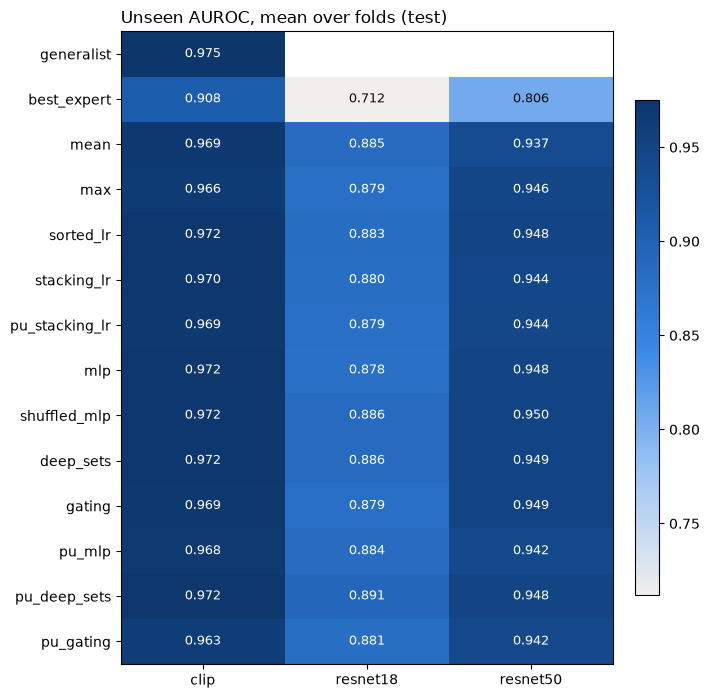

In [7]:
plot_summary(summary(results, "auc", MERGE_SIBLINGS), f"Unseen AUROC, mean over folds ({EVAL_POOL})")


### Seen minus unseen AUROC

On `meta_val` the seen images were used for early stopping, so this gap is only final on `test`.


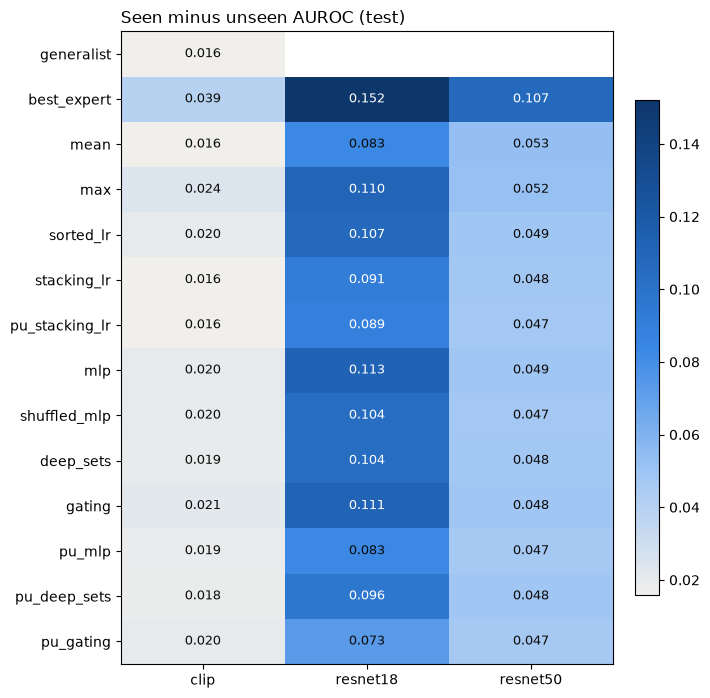

In [8]:
plot_summary(summary(results, "gap", MERGE_SIBLINGS), f"Seen minus unseen AUROC ({EVAL_POOL})")


### Accuracy at the threshold chosen on seen validation images


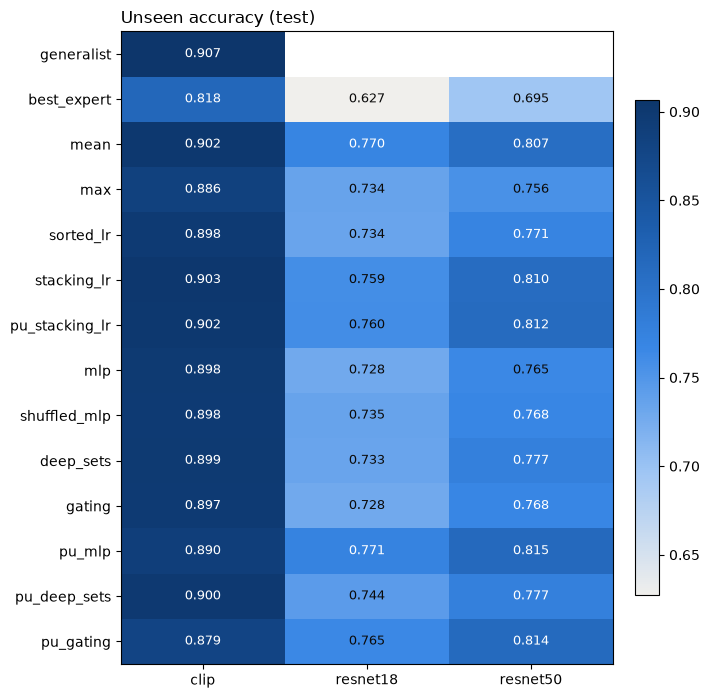

In [9]:
plot_summary(summary(results, "acc", MERGE_SIBLINGS), f"Unseen accuracy ({EVAL_POOL})")


## Are the differences real? (paired bootstrap)

Redraws the held-out images 1000 times and recomputes each comparison on the same redraws (`meta/bootstrap.py`).
`difference` is the first minus the second in mean unseen AUROC; `clear` means the 95% interval `low`-`high`
excludes 0. The comparisons are fixed in advance in `COMPARISONS`. Only image sampling is covered: the experts
were trained once.

In [10]:
from meta.bootstrap import run_bootstrap

bootstrap = run_bootstrap(eval_pool=EVAL_POOL, merge_siblings=MERGE_SIBLINGS)
bootstrap.round(4)

,question,comparison,difference,low,high,first_better_share,clear
0,RQ1,mean (clip) vs best_expert (clip),0.0609,0.0583,0.0637,1.000,True
1,RQ1,mlp (clip) vs best_expert (clip),0.0641,0.0615,0.0671,1.000,True
2,RQ1,mean (resnet18) vs best_expert (resnet18),0.1728,0.1680,0.1775,1.000,True
3,RQ1,mlp (resnet18) vs best_expert (resnet18),0.1660,0.1603,0.1717,1.000,True
4,RQ1,mean (resnet50) vs best_expert (resnet50),0.1309,0.1269,0.1346,1.000,True
5,RQ1,mlp (resnet50) vs best_expert (resnet50),0.1425,0.1379,0.1466,1.000,True
6,RQ1,generalist (clip) vs mean (clip),0.0061,0.0051,0.0069,1.000,True
7,RQ1,generalist (clip) vs sorted_lr (clip),0.0036,0.0026,0.0046,1.000,True
8,RQ1,generalist (clip) vs mlp (clip),0.0029,0.0018,0.0039,1.000,True
9,RQ1,generalist (clip) vs deep_sets (clip),0.0032,0.0023,0.0042,1.000,True
